# Introduction to Machine Learning – Lab 3
## Loadings, Cluster Profiles and New Houses

### Objective
Notebooks 08 to 09 reduced the houses with PCA and grouped them with k-means. This notebook asks what the results mean:
1. **Loadings:** which original features build the most important principal components?
2. **Cluster profiles:** what kind of houses does each cluster contain?
3. **New houses:** to which cluster do invented, plausible houses belong, is that intuitively right, and why must a new house first pass through the PCA?

Two preparations are compared throughout, because notebook 09 showed that the scaling changes the clusters most: **min-max** (notebook 08) and **z-score** on the ordinal and numeric columns (notebook 08.1). The clusterings are the ones chosen there: 5 clusters on 90% of the variance.

In [1]:
import sys
from pathlib import Path

# Add project root and notebooks/ to system path
sys.path.append(str(Path(".").resolve()))
sys.path.append(str(Path("notebooks").resolve()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from clustering import AXIS, BLUE, CLUSTER_COLORS, GRID, INK, MUTED, ORANGE, fit_models, reduce_to_thresholds, style_axes
from matplotlib.patches import Patch
from matplotlib.ticker import StrMethodFormatter
from preprocessing import (
    CLASS_NAMES,
    ORDINAL,
    TARGET,
    drop_incomplete,
    fill_missing,
    load_raw,
    make_preprocessor,
    make_scaler,
    make_zscore_scaler,
    prepare_data,
)
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

DATA_PATH = Path("../data/AmesHousing.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/AmesHousing.csv")

N_CLUSTERS = 5
THRESHOLD = 0.90

# One color per column type, and one per price class from the most expensive (blue) to the cheapest
TYPE_COLORS = {"One-hot": BLUE, "Ordinal": ORANGE, "Numeric": MUTED}
PRICE_COLORS = ["#CC79A7", "#D55E00", "#E69F00", "#F0E442", "#009E73", "#0072B2"]

### Data preparation
The same steps as in notebooks 08 and 08.1. The only difference: the encoder and the scalers are kept as fitted objects, because the invented houses in Section 3 have to pass through exactly the same steps as the real ones.

In [2]:
X, y = prepare_data(DATA_PATH, drop_extreme=True, drop_near_constant=True)
X_complete, y_complete = drop_incomplete(X, y)
X_complete = fill_missing(X_complete)
# The sale price is not used for the clustering, only to describe the clusters afterwards
price = load_raw(DATA_PATH).loc[X_complete.index, TARGET]

# The fitted steps are kept as objects, because new houses have to pass through exactly these
encoder = make_preprocessor("onehot", min_frequency=5).fit(X_complete, y_complete)
encoded_complete = encoder.transform(X_complete)
columns = encoded_complete.columns
onehot = [col for col in columns if col not in X_complete.columns]
ordinal = [col for col in columns if col in ORDINAL]
numeric = [col for col in columns if col not in onehot + ordinal]
column_type = pd.Series("Numeric", index=columns)
column_type[onehot] = "One-hot"
column_type[ordinal] = "Ordinal"

# Fitted on all houses: k-means has no train/test split (as in notebooks 08 and 08.1)
scalers = {
    "Min-max": make_scaler().fit(encoded_complete),
    "Z-score": make_zscore_scaler(ordinal + numeric).fit(encoded_complete),
}


def scale(name, encoded):
    """Scale encoded houses with the fitted scaler; z-score moves columns, so the order is restored."""
    return scalers[name].transform(encoded)[columns]


fits = {}
for name in scalers:
    pca, reduced, counts = reduce_to_thresholds(scale(name, encoded_complete))
    fits[name] = {"pca": pca, "reduced": reduced, "counts": counts, "models": fit_models(reduced, counts, N_CLUSTERS)}

for name, fit in fits.items():
    sizes = np.bincount(fit["models"][THRESHOLD].labels_).tolist()
    print(f"{name}: {fit['counts'][THRESHOLD]} components at 90%, cluster sizes {sizes}")

Min-max: 59 components at 90%, cluster sizes [601, 531, 687, 555, 549]
Z-score: 45 components at 90%, cluster sizes [657, 588, 166, 860, 652]


The cluster sizes are the same as in notebook 08 (601, 531, 687, 555, 549), so the cluster numbers below mean the same clusters as in the scatter plots there.

### 1. Loadings of the principal components
PCA describes every component by a vector of **weights** `pca.components_`, one per column. Each weight vector has length 1, so the weights only give a direction and say nothing about how much the houses vary along it. The **loadings** multiply the weights by the standard deviation of the component:

$$\text{loading}_{jk} = w_{jk} \cdot \sqrt{\lambda_k} \qquad \texttt{loadings = pca.components\_.T * np.sqrt(pca.explained\_variance\_)}$$

where $\lambda_k$ is the variance of component $k$. A loading is the covariance of column $j$ with component $k$, divided by the standard deviation of the component. A large positive loading means: houses with a high value in this column lie far on the positive side of the component.

In [3]:
def loadings_of(pca):
    """Loadings of every column on every component: the weights times the spread of the component."""
    values = pca.components_.T * np.sqrt(pca.explained_variance_)
    names = [f"PC{number}" for number in range(1, pca.n_components_ + 1)]
    return pd.DataFrame(values, index=columns, columns=names)


loadings = {name: loadings_of(fit["pca"]) for name, fit in fits.items()}

# The squared loadings of a component add up to its variance
for name, table in loadings.items():
    assert np.allclose((table**2).sum(), fits[name]["pca"].explained_variance_)

# Under z-score, the loading of a scaled column is its correlation with the component
z_scaled = scale("Z-score", encoded_complete)
pc1_scores = pd.Series(fits["Z-score"]["reduced"][:, 0], index=z_scaled.index)
correlation = z_scaled[ordinal + numeric].corrwith(pc1_scores)
gap = (correlation - loadings["Z-score"].loc[ordinal + numeric, "PC1"]).abs().max()
print(f"Z-score: largest gap between loading and correlation with PC1: {gap:.4f}")

# Under min-max, it is the correlation times the standard deviation of the scaled column
mm_scaled = scale("Min-max", encoded_complete)
pc1_scores = pd.Series(fits["Min-max"]["reduced"][:, 0], index=mm_scaled.index)
for col in ["Foundation_PConc", "Overall Qual", "Lot Area"]:
    corr = mm_scaled[col].corr(pc1_scores)
    print(
        f"Min-max, {col}: correlation with PC1 {corr:+.3f}, standard deviation {mm_scaled[col].std():.3f}, "
        f"loading {loadings['Min-max'].loc[col, 'PC1']:+.3f}"
    )

Z-score: largest gap between loading and correlation with PC1: 0.0001
Min-max, Foundation_PConc: correlation with PC1 +0.778, standard deviation 0.497, loading +0.387
Min-max, Overall Qual: correlation with PC1 +0.716, standard deviation 0.156, loading +0.112
Min-max, Lot Area: correlation with PC1 +0.098, standard deviation 0.036, loading +0.004


In [4]:
def top_loadings(table, n_components=3, top=8):
    """The columns with the largest absolute loadings on each of the first components, with their sign."""
    result = {}
    for pc in table.columns[:n_components]:
        strongest = table[pc].abs().nlargest(top).index
        result[pc] = [f"{col} ({table.loc[col, pc]:+.2f})" for col in strongest]
    return pd.DataFrame(result, index=pd.RangeIndex(1, top + 1, name="Rank"))


for name, table in loadings.items():
    print(f"{name}: largest loadings on PC1–PC3")
    with pd.option_context("display.max_colwidth", None):
        display(top_loadings(table))

Min-max: largest loadings on PC1–PC3


,PC1,PC2,PC3
Rank,,,
1,Foundation_PConc (+0.39),House Style_1Story (+0.38),House Style_1Story (+0.26)
2,Exterior 1st_VinylSd (+0.34),MS SubClass_20 (+0.37),House Style_2Story (-0.23)
3,Exterior 2nd_VinylSd (+0.33),House Style_2Story (-0.29),Mas Vnr Type_BrkFace (-0.20)
4,Garage Type_Attchd (+0.26),Foundation_CBlock (+0.25),MS SubClass_60 (-0.19)
5,Garage Type_Detchd (-0.26),Garage Type_Attchd (+0.22),Foundation_CBlock (-0.18)
6,Year Remod/Add (+0.24),MS Zoning_RL (+0.20),MS SubClass_20 (+0.17)
7,Mas Vnr Type_None (-0.24),MS SubClass_60 (-0.17),Exterior 1st_HdBoard (-0.16)
8,Foundation_CBlock (-0.24),2nd Flr SF (-0.16),Exterior 1st_VinylSd (+0.16)


Z-score: largest loadings on PC1–PC3


,PC1,PC2,PC3
Rank,,,
1,Overall Qual (+0.83),2nd Flr SF (+0.74),Lot Area (+0.50)
2,Garage Cars (+0.78),TotRms AbvGrd (+0.67),Fireplaces (+0.47)
3,Year Built (+0.77),Bedroom AbvGr (+0.62),1st Flr SF (+0.46)
4,Garage Yr Blt (+0.76),Gr Liv Area (+0.58),Lot Frontage (+0.45)
5,Exter Qual (+0.76),BsmtFin Type 1 (-0.53),Garage Yr Blt (-0.40)
6,Garage Area (+0.74),BsmtFin SF 1 (-0.52),Year Built (-0.38)
7,Bsmt Qual (+0.73),Bsmt Full Bath (-0.50),Year Remod/Add (-0.37)
8,Kitchen Qual (+0.71),Full Bath (+0.43),Gr Liv Area (+0.37)


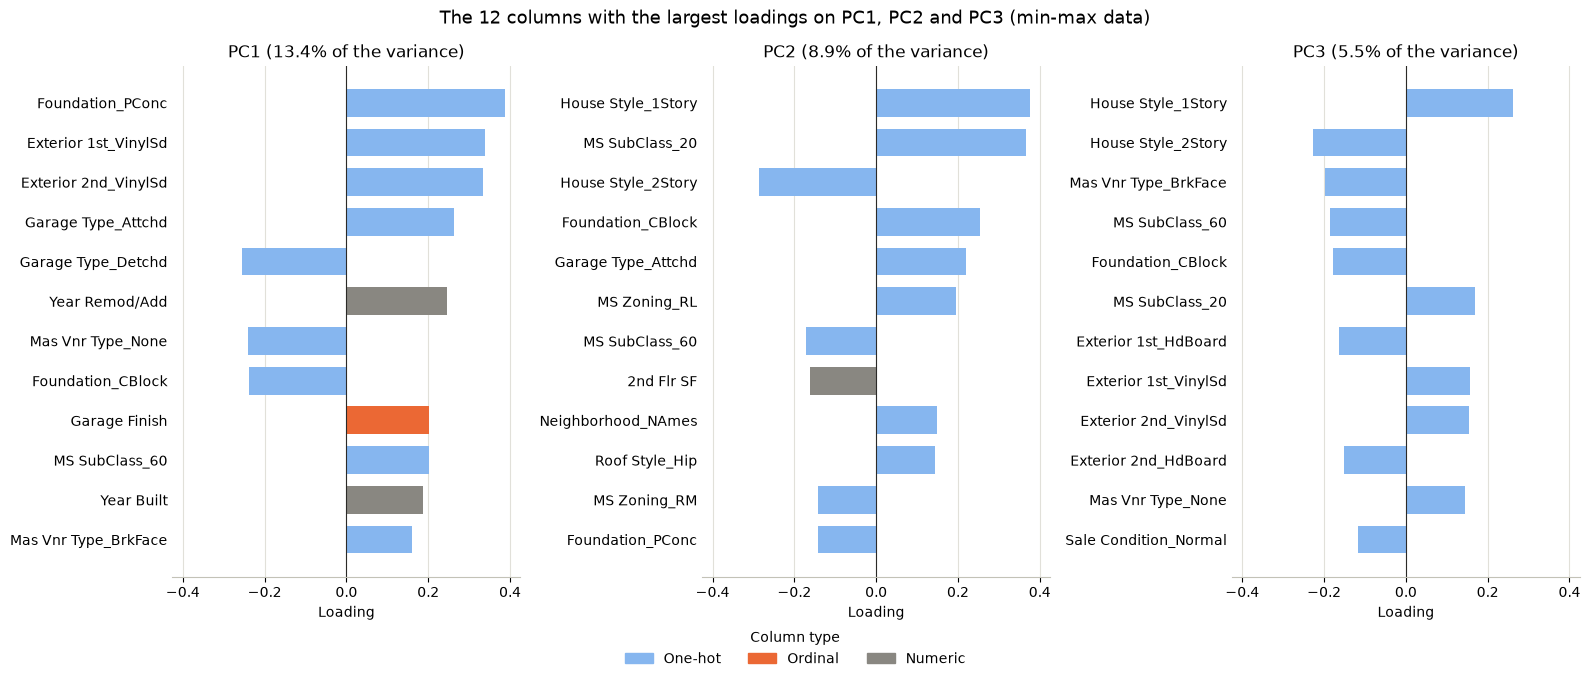

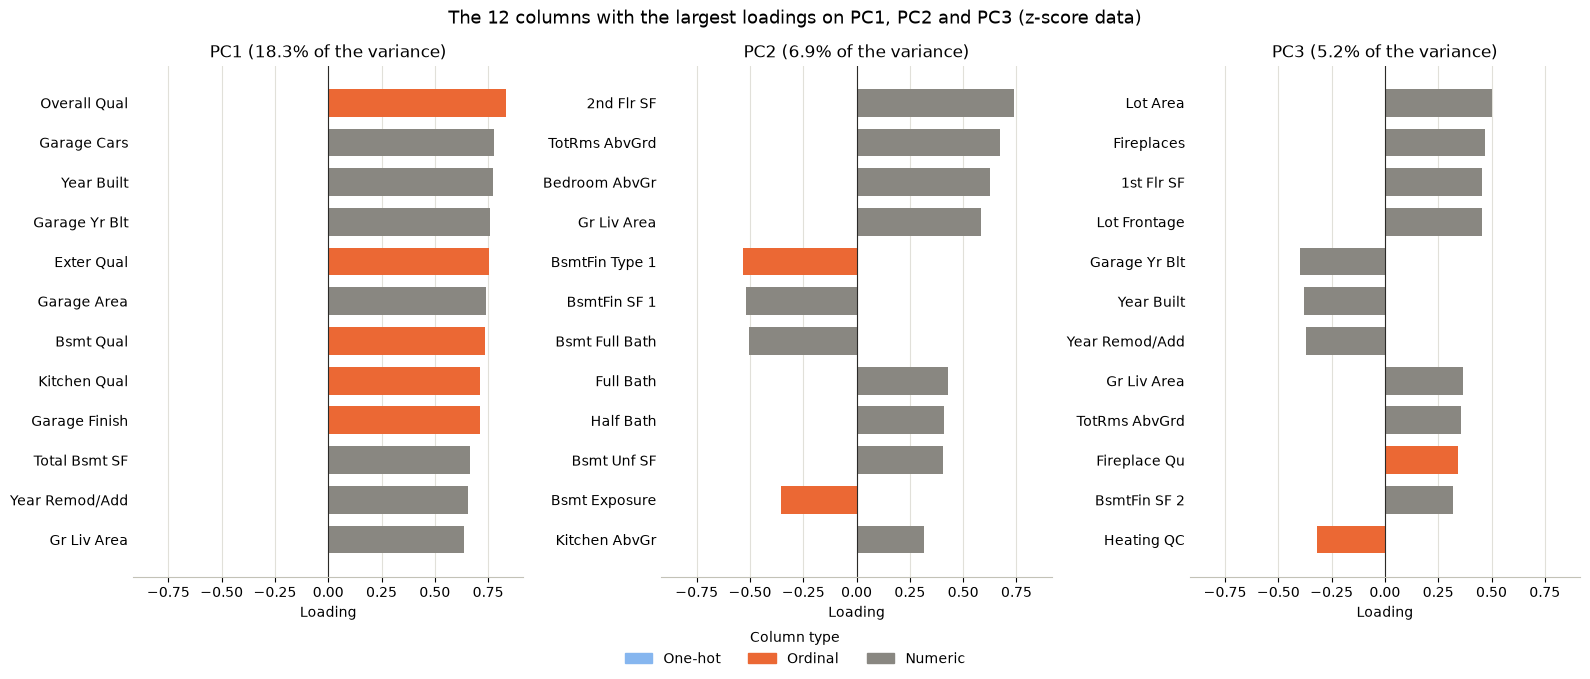

In [5]:
def plot_loadings(name, n_components=3, top=12):
    """Draw the columns with the largest loadings on the first components, colored by column type."""
    table, pca = loadings[name], fits[name]["pca"]
    fig, axes = plt.subplots(1, n_components, figsize=(16, 6.8))
    limit = table.iloc[:, :n_components].abs().max().max() * 1.1
    for number, ax in enumerate(axes):
        pc = table.columns[number]
        strongest = table[pc].abs().nlargest(top).index
        values = table.loc[strongest, pc][::-1]
        ax.barh(values.index, values, height=0.7, color=[TYPE_COLORS[column_type[col]] for col in values.index])
        ax.axvline(0, color=INK, linewidth=0.8)
        ax.set_xlim(-limit, limit)
        ax.set_title(f"{pc} ({pca.explained_variance_ratio_[number]:.1%} of the variance)", fontsize=12)
        ax.set_xlabel("Loading")
        style_axes(ax, grid="x")
    handles = [Patch(color=color, label=label) for label, color in TYPE_COLORS.items()]
    fig.legend(handles=handles, title="Column type", loc="lower center", ncol=3, frameon=False)
    fig.suptitle(f"The {top} columns with the largest loadings on PC1, PC2 and PC3 ({name.lower()} data)", fontsize=13)
    plt.tight_layout(rect=(0, 0.06, 1, 1))
    plt.show()


plot_loadings("Min-max")
plot_loadings("Z-score")

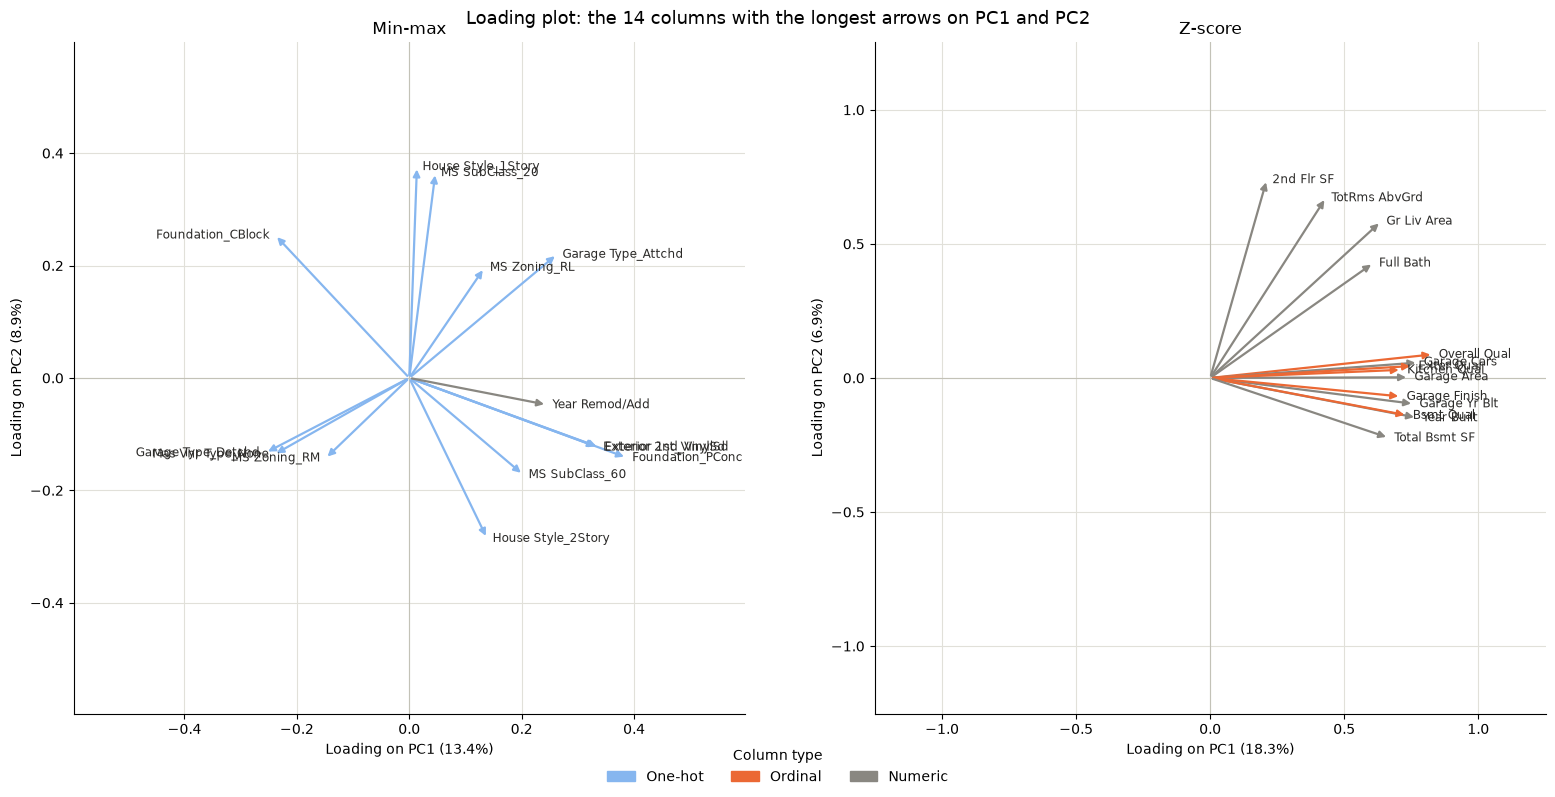

In [6]:
def plot_loading_arrows(ax, name, top=14):
    """Draw each strong column as an arrow from the origin to its loadings on PC1 and PC2."""
    table, pca = loadings[name], fits[name]["pca"]
    length = np.hypot(table["PC1"], table["PC2"])
    for col in length.nlargest(top).index:
        x, y_ = table.loc[col, "PC1"], table.loc[col, "PC2"]
        color = TYPE_COLORS[column_type[col]]
        ax.annotate("", (x, y_), (0, 0), arrowprops={"arrowstyle": "-|>", "color": color, "linewidth": 1.6})
        ax.annotate(col, (x, y_), xytext=(4 if x >= 0 else -4, 0), textcoords="offset points",
                    ha="left" if x >= 0 else "right", va="center", fontsize=8.5, color=INK)
    limit = length.max() * 1.45
    ax.set_xlim(-limit, limit)
    ax.set_ylim(-limit, limit)
    ax.axhline(0, color=AXIS, linewidth=0.8)
    ax.axvline(0, color=AXIS, linewidth=0.8)
    ax.set_aspect("equal")
    first, second = pca.explained_variance_ratio_[:2]
    ax.set_title(f"{name}", fontsize=12)
    ax.set_xlabel(f"Loading on PC1 ({first:.1%})")
    ax.set_ylabel(f"Loading on PC2 ({second:.1%})")
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)


fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, name in zip(axes, loadings):
    plot_loading_arrows(ax, name)
handles = [Patch(color=color, label=label) for label, color in TYPE_COLORS.items()]
fig.legend(handles=handles, title="Column type", loc="lower center", ncol=3, frameon=False)
fig.suptitle("Loading plot: the 14 columns with the longest arrows on PC1 and PC2", fontsize=13)
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

In [7]:
# How much of each component comes from each column type (squared loadings add up to the variance)
rows = []
for name, table in loadings.items():
    squared = table.iloc[:, :3] ** 2
    shares = squared.groupby(column_type).sum() / squared.sum()
    for pc in shares.columns:
        rows.append({"Preparation": name, "Component": pc, **shares[pc].round(3).to_dict()})
display(pd.DataFrame(rows).set_index(["Preparation", "Component"])[list(TYPE_COLORS)])

One-hot  Ordinal  Numeric
Preparation Component                           
Min-max     PC1          0.737    0.137    0.126
            PC2          0.913    0.024    0.063
            PC3          0.903    0.029    0.068
Z-score     PC1          0.060    0.422    0.518
            PC2          0.080    0.191    0.729
            PC3          0.086    0.205    0.710

#### Interpretation of the loadings
- **What a loading is in each preparation:** under z-score every ordinal and numeric column has standard deviation 1, so its loading is exactly its **correlation** with the component (largest gap: 0.0001). Under min-max a loading is the correlation **times the standard deviation** of the column. `Overall Qual` correlates with PC1 almost as strongly as `Foundation_PConc` (0.716 against 0.778), but its min-max spread is only 0.156 against 0.497, so its loading is 0.112 instead of 0.387. `Lot Area` is squeezed by its extreme houses (spread 0.036) and gets almost nothing (0.004). This is why the one-hot columns dominate the min-max components: they are the columns with the largest spread.
- **Min-max PC1 (13.4%): new against old construction.** Positive: `Foundation_PConc` (+0.39), vinyl siding (`Exterior 1st/2nd_VinylSd`, +0.34 / +0.33), an attached garage (+0.26), a recent `Year Remod/Add` (+0.24). Negative: a detached garage (−0.26), no masonry veneer (−0.24), a cinder-block foundation (−0.24). These are the materials of houses built after about 1990 against older ones. One-hot columns make up 73.7% of PC1.
- **Min-max PC2 (8.9%): one story against two.** Positive: `House Style_1Story` (+0.38), `MS SubClass_20` (one-story, 1946 and newer, +0.37), `Foundation_CBlock` (+0.25). Negative: `House Style_2Story` (−0.29), `MS SubClass_60` (−0.17), `2nd Flr SF` (−0.16). One-hot columns make up 91.3%.
- **Min-max PC3 (5.5%):** again one story against two, but now combined with materials: `1Story` and vinyl siding on the positive side, `2Story`, brick veneer (`BrkFace`), hardboard siding (`HdBoard`) and cinder block on the negative side. It separates the two-story houses of the 1970s and 1980s from the rest.
- **Z-score PC1 (18.3%): quality and modernity.** All eight strongest loadings are positive and between 0.71 and 0.83: `Overall Qual`, `Garage Cars`, `Year Built`, `Garage Yr Blt`, `Exter Qual`, `Garage Area`, `Bsmt Qual`, `Kitchen Qual`. A house far on the right is new, well built and has a large garage. One-hot columns make up only 6.0%.
- **Z-score PC2 (6.9%): space above ground against a finished basement.** Positive: `2nd Flr SF` (+0.74), `TotRms AbvGrd` (+0.67), `Bedroom AbvGr` (+0.62), `Gr Liv Area` (+0.58). Negative: `BsmtFin Type 1` (−0.53), `BsmtFin SF 1` (−0.52), `Bsmt Full Bath` (−0.50). Two-story houses lie at the top, one-story houses with a finished basement at the bottom.
- **Z-score PC3:** large lots and a large ground floor (`Lot Area` +0.50, `Fireplaces` +0.47, `1st Flr SF` +0.46, `Lot Frontage` +0.45) against new houses (`Garage Yr Blt` −0.40, `Year Built` −0.38): older houses on large lots against new houses on small lots.
- **The same story, told by different columns:** both preparations put the age of the house on PC1 and the number of floors on PC2. Min-max sees them through the categories that come with age and style (foundation, siding, garage type, subclass), z-score through the numbers themselves (years, quality grades, areas).
- **Reading the loading plot:** arrows that point the same way belong to columns that rise and fall together. Under z-score the quality, garage and age arrows form one bundle along PC1, which is why one component can summarize them. Under min-max the categories of one feature point in opposite directions (`Garage Type_Attchd` against `Detchd`, `Foundation_PConc` against `CBlock`), because a house has either one or the other. The arrows of `Exterior 1st_VinylSd` and `Exterior 2nd_VinylSd` lie on top of each other: the two columns almost always agree. The z-score arrows are longer because those columns have standard deviation 1, while the min-max columns have at most 0.5.

### 2. Profiles of the clusters
To describe a cluster, the houses are looked at in their **original units** (years, ft², grades) and not in the scaled or PCA units. The sale price was not used for the clustering at all. It is shown here only to describe the clusters.

The first table gives typical values per cluster, the second table the categories that are much more frequent in a cluster than among all houses, and the figure shows the distributions of six features and the price classes of Lab 2 inside each cluster.

In [8]:
def profile(groups):
    """Typical values of the houses in each group, in the original units of the features."""
    grouped = X_complete.groupby(groups)
    table = pd.DataFrame(
        {
            "Houses": groups.value_counts(),
            "Median sale price": price.groupby(groups).median(),
            "Overall Qual (mean, 1–10)": grouped["Overall Qual"].mean(),
            "Kitchen Qual (mean, 1–5)": grouped["Kitchen Qual"].mean(),
            "Year Built (median)": grouped["Year Built"].median(),
            "Year Remod/Add (median)": grouped["Year Remod/Add"].median(),
            "Gr Liv Area (median, ft²)": grouped["Gr Liv Area"].median(),
            "Total Bsmt SF (median, ft²)": grouped["Total Bsmt SF"].median(),
            "Garage Area (median, ft²)": grouped["Garage Area"].median(),
            "Lot Area (median, ft²)": grouped["Lot Area"].median(),
            "Full Bath (mean)": grouped["Full Bath"].mean(),
            "Share with a 2nd floor": grouped["2nd Flr SF"].apply(lambda s: (s > 0).mean()),
        }
    )
    for feature in ["House Style", "Bldg Type", "Foundation", "Exterior 1st", "Garage Type", "MS Zoning", "Neighborhood"]:
        table[f"Most common {feature}"] = grouped[feature].agg(
            lambda s: f"{s.mode().iloc[0]} ({(s == s.mode().iloc[0]).mean():.0%})"
        )
    return table


def profile_with_total(labels):
    clusters = pd.Series(labels + 1, index=X_complete.index, name="Cluster")
    table = profile(clusters).sort_index()
    table.index = [f"Cluster {number}" for number in table.index]
    everyone = profile(pd.Series("All houses", index=X_complete.index))
    return pd.concat([table, everyone]).T


labels = {name: fit["models"][THRESHOLD].labels_ for name, fit in fits.items()}
profiles = {name: profile_with_total(values) for name, values in labels.items()}


def show(table):
    """Round the numeric cells for reading, keep the text cells."""
    formatted = table.copy().astype(object)
    for row in formatted.index:
        values = table.loc[row]
        if row.startswith("Share"):
            formatted.loc[row] = [f"{v:.0%}" for v in values]
        elif "mean" in row:
            formatted.loc[row] = [f"{v:.2f}" for v in values]
        elif not row.startswith("Most common"):
            formatted.loc[row] = [f"{v:,.0f}" for v in values]
    with pd.option_context("display.max_colwidth", None):
        display(formatted)


print("Min-max clusters (90% of the variance, 5 clusters), with the same numbers as in notebook 08:")
show(profiles["Min-max"])

Min-max clusters (90% of the variance, 5 clusters), with the same numbers as in notebook 08:


,Cluster 1,Cluster 2,Cluster 3,Cluster 4,Cluster 5,All houses
Houses,601,531,687,555,549,"2,923"
Median sale price,"120,000","219,210","140,500","225,000","150,000","160,000"
"Overall Qual (mean, 1–10)",5.14,7.11,5.31,7.39,5.80,6.09
"Kitchen Qual (mean, 1–5)",3.13,3.93,3.21,4.11,3.27,3.51
Year Built (median),"1,925","2,001","1,962","2,005","1,973","1,973"
Year Remod/Add (median),"1,950","2,002","1,968","2,005","1,977","1,993"
"Gr Liv Area (median, ft²)","1,328","1,870","1,148","1,506","1,400","1,441"
"Total Bsmt SF (median, ft²)",776,939,"1,056","1,491",855,990
"Garage Area (median, ft²)",297,554,438,575,462,480
"Lot Area (median, ft²)","8,064","10,237","9,819","9,541","9,069","9,430"


In [9]:
def over_represented(labels, top=5):
    """The categories whose share in a cluster exceeds their share among all houses by the most."""
    dummies = encoded_complete[onehot]
    overall = dummies.mean()
    rows = {}
    for cluster in range(N_CLUSTERS):
        share = dummies[labels == cluster].mean()
        strongest = (share - overall).nlargest(top).index
        rows[f"Cluster {cluster + 1}"] = [f"{col}: {share[col]:.0%} (all: {overall[col]:.0%})" for col in strongest]
    return pd.DataFrame(rows, index=pd.RangeIndex(1, top + 1, name="Rank")).T


with pd.option_context("display.max_colwidth", None):
    display(over_represented(labels["Min-max"]))

Rank,1,2,3,4,5
Cluster 1,Garage Type_Detchd: 74% (all: 27%),Foundation_BrkTil: 50% (all: 11%),MS Zoning_RM: 53% (all: 16%),Mas Vnr Type_None: 96% (all: 61%),House Style_1.5Fin: 44% (all: 11%)
Cluster 2,MS SubClass_60: 91% (all: 20%),House Style_2Story: 95% (all: 30%),Foundation_PConc: 97% (all: 45%),Exterior 1st_VinylSd: 81% (all: 35%),Exterior 2nd_VinylSd: 80% (all: 35%)
Cluster 3,MS SubClass_20: 97% (all: 37%),House Style_1Story: 100% (all: 51%),Foundation_CBlock: 89% (all: 43%),Neighborhood_NAmes: 44% (all: 15%),MS Zoning_RL: 98% (all: 78%)
Cluster 4,Foundation_PConc: 99% (all: 45%),House Style_1Story: 98% (all: 51%),Exterior 1st_VinylSd: 77% (all: 35%),Exterior 2nd_VinylSd: 76% (all: 35%),Garage Type_Attchd: 94% (all: 59%)
Cluster 5,Foundation_CBlock: 80% (all: 43%),Exterior 1st_HdBoard: 33% (all: 15%),Exterior 2nd_HdBoard: 31% (all: 14%),MS SubClass_160: 20% (all: 4%),House Style_SLvl: 19% (all: 4%)


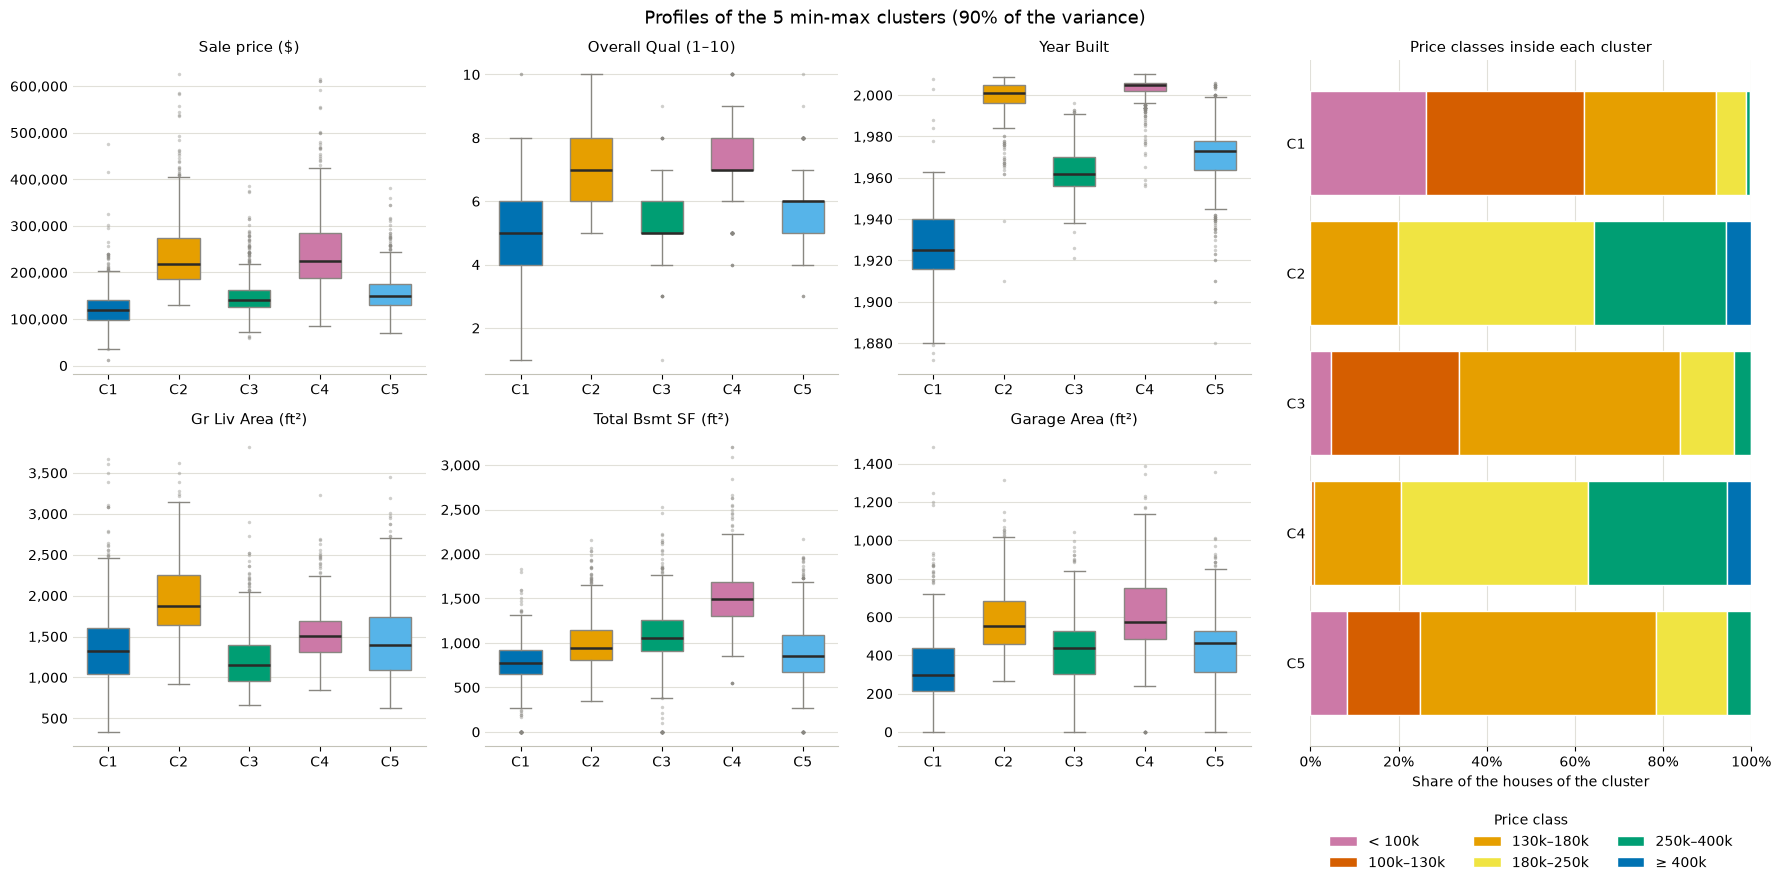

In [10]:
def plot_profiles(labels, title):
    """Box plots of six features per cluster, and the price classes inside each cluster."""
    features = [
        (price, "Sale price ($)"),
        (X_complete["Overall Qual"], "Overall Qual (1–10)"),
        (X_complete["Year Built"], "Year Built"),
        (X_complete["Gr Liv Area"], "Gr Liv Area (ft²)"),
        (X_complete["Total Bsmt SF"], "Total Bsmt SF (ft²)"),
        (X_complete["Garage Area"], "Garage Area (ft²)"),
    ]
    fig, axes = plt.subplots(2, 4, figsize=(18, 9), gridspec_kw={"width_ratios": [1, 1, 1, 1.25]})
    feature_axes = [axes[0, 0], axes[0, 1], axes[0, 2], axes[1, 0], axes[1, 1], axes[1, 2]]
    names = [f"C{number}" for number in range(1, N_CLUSTERS + 1)]
    for ax, (values, label) in zip(feature_axes, features):
        parts = ax.boxplot(
            [values[labels == cluster] for cluster in range(N_CLUSTERS)],
            tick_labels=names,
            widths=0.6,
            patch_artist=True,
            medianprops={"color": INK, "linewidth": 1.8},
            whiskerprops={"color": MUTED},
            capprops={"color": MUTED},
            flierprops={"marker": "o", "markersize": 2.5, "markerfacecolor": MUTED, "markeredgecolor": "none", "alpha": 0.4},
        )
        for box, color in zip(parts["boxes"], CLUSTER_COLORS):
            box.set_facecolor(color)
            box.set_edgecolor(MUTED)
        ax.set_title(label, fontsize=11)
        ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
        style_axes(ax)

    gs = axes[0, 3].get_gridspec()
    for ax in axes[:, 3]:
        ax.remove()
    ax = fig.add_subplot(gs[:, 3])
    shares = pd.crosstab(labels + 1, y_complete, normalize="index")
    left = np.zeros(N_CLUSTERS)
    for price_class in range(len(CLASS_NAMES)):
        values = shares.get(price_class, pd.Series(0, index=shares.index)).to_numpy()
        ax.barh(names, values, left=left, color=PRICE_COLORS[price_class], edgecolor="white", label=CLASS_NAMES[price_class])
        left += values
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:.0%}"))
    ax.set_title("Price classes inside each cluster", fontsize=11)
    ax.set_xlabel("Share of the houses of the cluster")
    ax.legend(title="Price class", frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3)
    style_axes(ax, grid="x")
    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()


plot_profiles(labels["Min-max"], "Profiles of the 5 min-max clusters (90% of the variance)")

#### Interpretation of the min-max clusters
The five clusters split the houses by **construction period** and by **number of floors**, which are exactly PC1 and PC2:

- **Cluster 1: old houses from before the war (601 houses).** Median year 1925, often 1.5 stories (`1.5Fin` 44%, 68% have a second floor). Brick-and-tile foundation (`BrkTil` 50% against 11% of all houses), wood siding, no masonry veneer (96%), a detached garage (74% against 27%) and the smallest garages (297 ft²). Small lots in the denser `RM` zone (53% against 16%), most often in `OldTown` (37%). Average quality 5.1. The cheapest cluster: median price 120,000, about 60% of its houses are below 130k.
- **Cluster 3: one-story ranch houses of the 1960s (687 houses).** Median year 1962, 100% one story, 97% `MS SubClass_20`. Cinder-block foundation (89%), often hardboard siding, an attached garage. The smallest living area (1,148 ft²) but a full basement (1,056 ft²). 44% are in `NAmes`. Average quality 5.3, median price 140,500.
- **Cluster 5: the mixed houses of the 1970s (549 houses).** Median year 1973, cinder block (80%), hardboard siding (33% against 15%). Half have a second floor (56%), split-levels (19% against 4%) and two-story townhouses (`MS SubClass_160`, 20% against 4%) are frequent, and only 52% are single-family houses. Average quality 5.8, median price 150,000. This cluster has no single clear style, which matches its position in the middle of the scatter plots and its weak silhouette in notebook 08.
- **Cluster 2: modern two-story family houses (531 houses).** Median year 2001, 95% two stories, 91% `MS SubClass_60`. Poured-concrete foundation (97%) and vinyl siding (81%). The largest living area (1,870 ft²), two full bathrooms on average, quality 7.1. Most often in `Gilbert` (25%). Median price 219,210.
- **Cluster 4: modern one-story houses (555 houses).** Median year 2005, 98% one story, poured concrete (99%), vinyl siding (77%), an attached garage (94%). The largest basement (1,491 ft²) and the highest quality (7.4). 29% are not single-family houses: they are new one-story townhouses. Most often in `CollgCr` (24%). Median price 225,000.

**The price follows the clusters, although it was not used:** the median price rises from 120,000 (cluster 1) to 140,500, 150,000, 219,210 and 225,000 (cluster 4). Age and building materials go together with quality, and quality with price. But the clusters are no price classes: every cluster spans several price classes, and the most expensive houses (≥ 400k) are split between the two modern clusters 2 and 4, which differ by the number of floors and not by price.

Z-score clusters (90% of the variance, 5 clusters):


,Cluster 1,Cluster 2,Cluster 3,Cluster 4,Cluster 5,All houses
Houses,657,588,166,860,652,"2,923"
Median sale price,"124,000","233,778","99,750","143,222","211,000","160,000"
"Overall Qual (mean, 1–10)",5.21,7.54,4.60,5.37,6.99,6.09
"Kitchen Qual (mean, 1–5)",3.13,4.15,3.02,3.19,3.85,3.51
Year Built (median),"1,937","2,005","1,940","1,965","1,999","1,973"
Year Remod/Add (median),"1,957","2,005","1,970","1,973","2,000","1,993"
"Gr Liv Area (median, ft²)","1,348","1,566","1,113","1,126","1,882","1,441"
"Total Bsmt SF (median, ft²)",756,"1,530",784,"1,040",919,990
"Garage Area (median, ft²)",330,578,0,441,530,480
"Lot Area (median, ft²)","8,146","10,120","8,050","9,600","10,250","9,430"


Rank,1,2,3,4,5
Cluster 1,Garage Type_Detchd: 72% (all: 27%),MS Zoning_RM: 46% (all: 16%),Mas Vnr Type_None: 89% (all: 61%),Foundation_BrkTil: 37% (all: 11%),House Style_1.5Fin: 35% (all: 11%)
Cluster 2,Foundation_PConc: 88% (all: 45%),House Style_1Story: 94% (all: 51%),Garage Type_Attchd: 98% (all: 59%),Exterior 1st_VinylSd: 66% (all: 35%),Exterior 2nd_VinylSd: 65% (all: 35%)
Cluster 3,Garage Type_NA: 95% (all: 5%),Central Air_N: 39% (all: 7%),Mas Vnr Type_None: 91% (all: 61%),MS Zoning_RM: 34% (all: 16%),Neighborhood_Edwards: 23% (all: 7%)
Cluster 4,Foundation_CBlock: 84% (all: 43%),MS SubClass_20: 68% (all: 37%),House Style_1Story: 75% (all: 51%),Neighborhood_NAmes: 37% (all: 15%),MS Zoning_RL: 93% (all: 78%)
Cluster 5,House Style_2Story: 90% (all: 30%),MS SubClass_60: 80% (all: 20%),Foundation_PConc: 83% (all: 45%),Exterior 1st_VinylSd: 64% (all: 35%),Exterior 2nd_VinylSd: 64% (all: 35%)


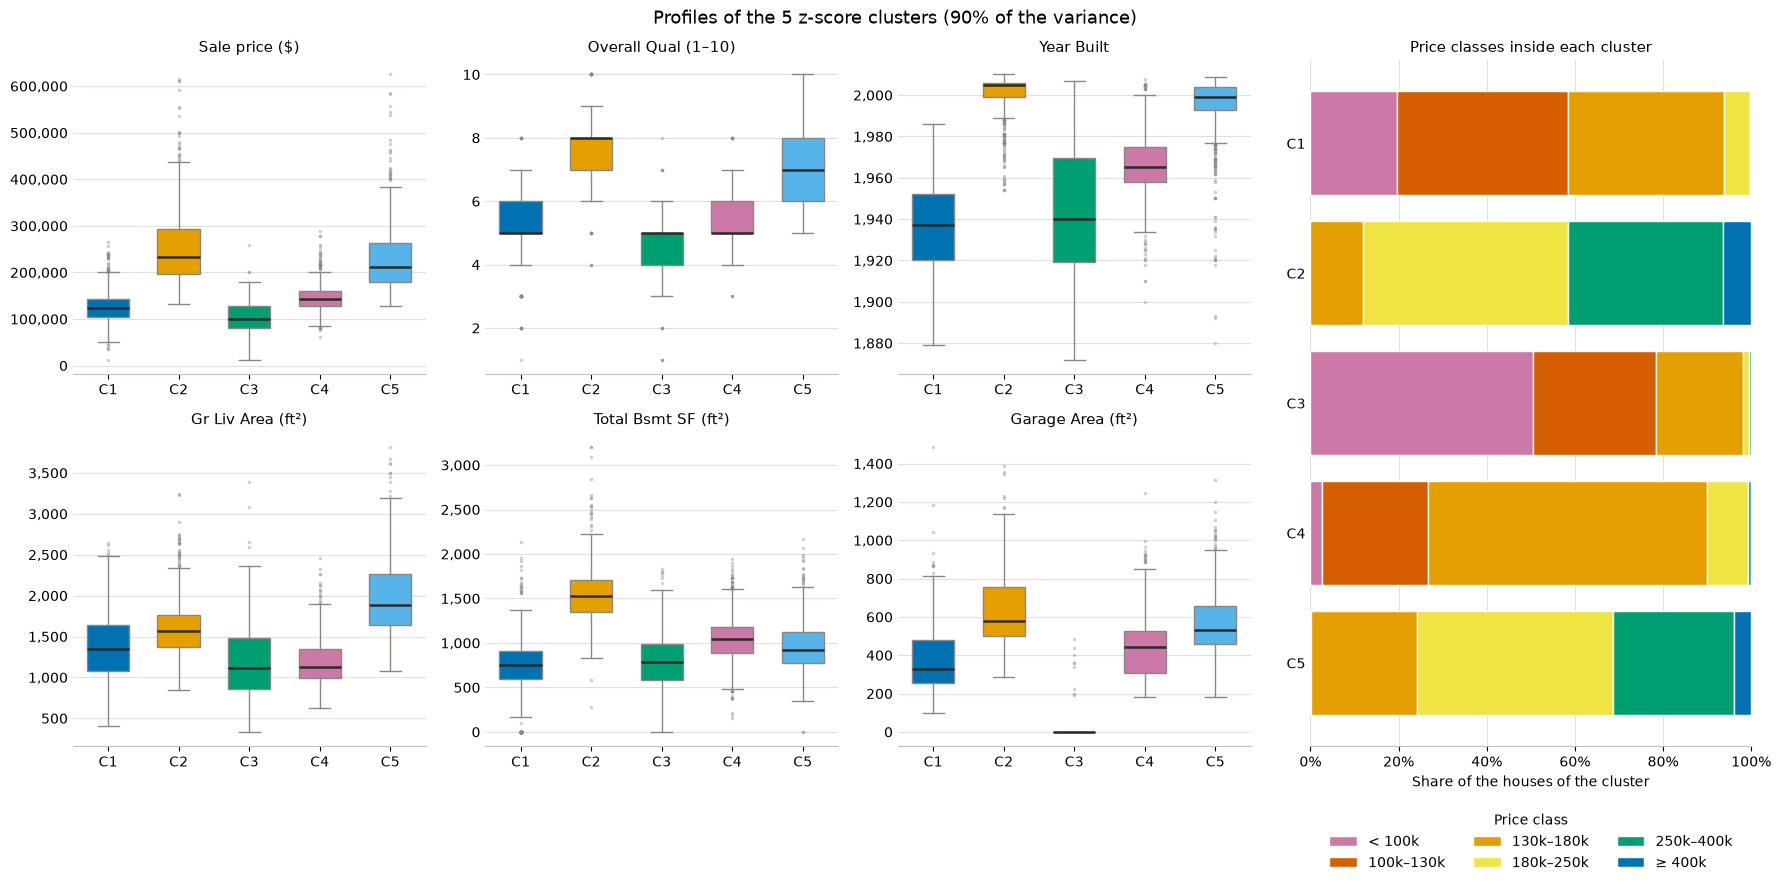

Houses per pair of clusters:


Z-score cluster,1,2,3,4,5
Min-max cluster,,,,,
1,454,0,99,34,14
2,4,18,0,6,503
3,62,49,17,557,2
4,0,499,13,41,2
5,137,22,37,222,131


In [11]:
print("Z-score clusters (90% of the variance, 5 clusters):")
show(profiles["Z-score"])
with pd.option_context("display.max_colwidth", None):
    display(over_represented(labels["Z-score"]))
plot_profiles(labels["Z-score"], "Profiles of the 5 z-score clusters (90% of the variance)")

overlap = pd.crosstab(
    pd.Series(labels["Min-max"] + 1, name="Min-max cluster"), pd.Series(labels["Z-score"] + 1, name="Z-score cluster")
)
print("Houses per pair of clusters:")
display(overlap)

#### Interpretation of the z-score clusters
Four of the five z-score clusters match a min-max cluster, and one is new:

- **Z1, old houses (657)** ≈ min-max cluster 1: median year 1937, detached garage (72%), `1.5Fin`, `RM`, `OldTown`. Median price 124,000. 454 of its houses are in min-max cluster 1.
- **Z4, houses of the 1960s (860)** ≈ min-max cluster 3: cinder block (84%), mostly one story, `NAmes`. Median price 143,222. It also takes 222 houses of min-max cluster 5.
- **Z5, modern two-story houses (652)** ≈ min-max cluster 2: median year 1999, 90% two stories. Median price 211,000. 503 houses come from min-max cluster 2.
- **Z2, modern one-story houses of high quality (588)** ≈ min-max cluster 4: median year 2005, 94% one story, attached garage (98%), quality 7.5, often `NridgHt`. The most expensive cluster: median price 233,778.
- **Z3, houses without a garage (166), new:** 95% have no garage (against 5% of all houses), 39% have no central air (against 7%), and they are frequent in `Edwards`. Quality 4.6 and the lowest median price, 99,750.

**Why the no-garage cluster only appears under z-score:** a house without a garage has 0 in `Garage Area`, `Garage Cars`, `Garage Finish`, `Garage Qual` and `Garage Cond` at the same time. Under z-score each of these columns has variance 1, so these houses lie several standard deviations away from the others in five columns at once, and k-means gives them a cluster of their own. Under min-max the same columns hold little of the variance, and the missing garage is only one more one-hot column (`Garage Type_NA`).

**What disappears:** the mixed 1970s cluster 5 of min-max has no counterpart. Its houses are spread over Z4 (222), Z1 (137) and Z5 (131), because under z-score the houses are grouped by age, quality and size, and the building types that held cluster 5 together count much less.

### 3. New houses
Six plausible houses are invented, each with all of its features set in a way that fits together (for example, `Gr Liv Area` is the sum of the floors and the garage year fits the garage type). Features that the description does not cover take the most common value or the median of the real houses.

| House | Description | Intuitive expectation |
|---|---|---|
| A | New luxury two-story house in `NridgHt`, quality 9, 2,950 ft², 3-car garage | modern two-story cluster, but it is far more expensive than a typical member |
| B | 1920 one-and-a-half-story house in `OldTown`, wood siding, brick foundation, detached 1-car garage | old houses |
| C | 1962 one-story ranch house in `NAmes`, cinder block, metal siding | 1960s ranch houses |
| D | 1999 two-story suburban house in `CollgCr`, quality 7 | modern two-story houses |
| E | 1915 two-story house in `Crawfor`, **fully remodeled in 2005**, quality 8 and condition 8, but still brick foundation, wood siding and a detached garage | unclear: old by construction, modern by quality |
| F | New small one-story townhouse (`TwnhsE`) in `Blmngtn`, 1,300 ft² | modern one-story houses |

In [12]:
# Starting point: the most common value of every category and grade and the median of every number.
# Each invented house then sets all values that describe it, so that its parts fit together
typical = {
    col: X_complete[col].mode().iloc[0] if col in ORDINAL or col in X_complete.select_dtypes("category") else X_complete[col].median()
    for col in X_complete.columns
}
no_extras = {"Wood Deck SF": 0, "Open Porch SF": 0, "Enclosed Porch": 0, "3Ssn Porch": 0, "Screen Porch": 0,
             "Pool Area": 0, "Misc Val": 0, "Low Qual Fin SF": 0, "Fence": 0, "Alley": "NA", "Sale Type": "WD ",
             "Sale Condition": "Normal", "Condition 1": "Norm", "Functional": 7, "Central Air": "Y", "Electrical": 4,
             "Kitchen AbvGr": 1, "Bsmt Half Bath": 0, "BsmtFin Type 2": 1, "BsmtFin SF 2": 0, "Paved Drive": 2,
             "Garage Qual": 3, "Garage Cond": 3, "Exter Cond": 3, "Bsmt Cond": 3, "Land Contour": "Lvl", "Land Slope": 2,
             "Lot Config": "Inside", "Yr Sold": 2008, "Mo Sold": 6}

invented = {
    "A: new luxury house": {
        "MS SubClass": "60", "MS Zoning": "RL", "Neighborhood": "NridgHt", "Bldg Type": "1Fam", "House Style": "2Story",
        "Lot Frontage": 95, "Lot Area": 13500, "Lot Shape": 2, "Overall Qual": 9, "Overall Cond": 5,
        "Year Built": 2007, "Year Remod/Add": 2007, "Roof Style": "Hip", "Exterior 1st": "VinylSd", "Exterior 2nd": "VinylSd",
        "Mas Vnr Type": "Stone", "Mas Vnr Area": 320, "Exter Qual": 5, "Foundation": "PConc",
        "Bsmt Qual": 5, "Bsmt Exposure": 3, "BsmtFin Type 1": 6, "BsmtFin SF 1": 1100, "Bsmt Unf SF": 500, "Total Bsmt SF": 1600,
        "Heating QC": 5, "1st Flr SF": 1650, "2nd Flr SF": 1300, "Gr Liv Area": 2950, "Bsmt Full Bath": 1,
        "Full Bath": 3, "Half Bath": 1, "Bedroom AbvGr": 4, "Kitchen Qual": 5, "TotRms AbvGrd": 11,
        "Fireplaces": 1, "Fireplace Qu": 4, "Garage Type": "Attchd", "Garage Yr Blt": 2007, "Garage Finish": 3,
        "Garage Cars": 3, "Garage Area": 900, "Wood Deck SF": 220, "Open Porch SF": 80,
        "Sale Type": "New", "Sale Condition": "Partial",
    },
    "B: pre-war 1.5-story house": {
        "MS SubClass": "50", "MS Zoning": "RM", "Neighborhood": "OldTown", "Bldg Type": "1Fam", "House Style": "1.5Fin",
        "Lot Frontage": 55, "Lot Area": 6600, "Lot Shape": 3, "Overall Qual": 5, "Overall Cond": 6,
        "Year Built": 1920, "Year Remod/Add": 1960, "Roof Style": "Gable", "Exterior 1st": "Wd Sdng", "Exterior 2nd": "Wd Sdng",
        "Mas Vnr Type": "None", "Mas Vnr Area": 0, "Exter Qual": 3, "Foundation": "BrkTil",
        "Bsmt Qual": 3, "Bsmt Exposure": 1, "BsmtFin Type 1": 1, "BsmtFin SF 1": 0, "Bsmt Unf SF": 750, "Total Bsmt SF": 750,
        "Heating QC": 3, "Electrical": 3, "1st Flr SF": 900, "2nd Flr SF": 450, "Gr Liv Area": 1350, "Bsmt Full Bath": 0,
        "Full Bath": 1, "Half Bath": 0, "Bedroom AbvGr": 3, "Kitchen Qual": 3, "TotRms AbvGrd": 6,
        "Fireplaces": 0, "Fireplace Qu": 0, "Garage Type": "Detchd", "Garage Yr Blt": 1955, "Garage Finish": 1,
        "Garage Cars": 1, "Garage Area": 260, "Enclosed Porch": 120, "Fence": 3,
    },
    "C: 1960s ranch house": {
        "MS SubClass": "20", "MS Zoning": "RL", "Neighborhood": "NAmes", "Bldg Type": "1Fam", "House Style": "1Story",
        "Lot Frontage": 70, "Lot Area": 9600, "Lot Shape": 3, "Overall Qual": 5, "Overall Cond": 6,
        "Year Built": 1962, "Year Remod/Add": 1962, "Roof Style": "Gable", "Exterior 1st": "MetalSd", "Exterior 2nd": "MetalSd",
        "Mas Vnr Type": "None", "Mas Vnr Area": 0, "Exter Qual": 3, "Foundation": "CBlock",
        "Bsmt Qual": 3, "Bsmt Exposure": 1, "BsmtFin Type 1": 3, "BsmtFin SF 1": 500, "Bsmt Unf SF": 560, "Total Bsmt SF": 1060,
        "Heating QC": 3, "1st Flr SF": 1060, "2nd Flr SF": 0, "Gr Liv Area": 1060, "Bsmt Full Bath": 1,
        "Full Bath": 1, "Half Bath": 0, "Bedroom AbvGr": 3, "Kitchen Qual": 3, "TotRms AbvGrd": 6,
        "Fireplaces": 0, "Fireplace Qu": 0, "Garage Type": "Attchd", "Garage Yr Blt": 1962, "Garage Finish": 1,
        "Garage Cars": 1, "Garage Area": 300,
    },
    "D: 1990s suburban house": {
        "MS SubClass": "60", "MS Zoning": "RL", "Neighborhood": "CollgCr", "Bldg Type": "1Fam", "House Style": "2Story",
        "Lot Frontage": 75, "Lot Area": 9500, "Lot Shape": 2, "Overall Qual": 7, "Overall Cond": 5,
        "Year Built": 1999, "Year Remod/Add": 2000, "Roof Style": "Gable", "Exterior 1st": "VinylSd", "Exterior 2nd": "VinylSd",
        "Mas Vnr Type": "BrkFace", "Mas Vnr Area": 150, "Exter Qual": 4, "Foundation": "PConc",
        "Bsmt Qual": 4, "Bsmt Exposure": 1, "BsmtFin Type 1": 6, "BsmtFin SF 1": 700, "Bsmt Unf SF": 250, "Total Bsmt SF": 950,
        "Heating QC": 5, "1st Flr SF": 960, "2nd Flr SF": 880, "Gr Liv Area": 1840, "Bsmt Full Bath": 1,
        "Full Bath": 2, "Half Bath": 1, "Bedroom AbvGr": 3, "Kitchen Qual": 4, "TotRms AbvGrd": 8,
        "Fireplaces": 1, "Fireplace Qu": 3, "Garage Type": "Attchd", "Garage Yr Blt": 1999, "Garage Finish": 2,
        "Garage Cars": 2, "Garage Area": 520, "Wood Deck SF": 150, "Open Porch SF": 50,
    },
    "E: old house, fully remodeled": {
        "MS SubClass": "70", "MS Zoning": "RL", "Neighborhood": "Crawfor", "Bldg Type": "1Fam", "House Style": "2Story",
        "Lot Frontage": 60, "Lot Area": 8400, "Lot Shape": 3, "Overall Qual": 8, "Overall Cond": 8,
        "Year Built": 1915, "Year Remod/Add": 2005, "Roof Style": "Gable", "Exterior 1st": "Wd Sdng", "Exterior 2nd": "Wd Sdng",
        "Mas Vnr Type": "None", "Mas Vnr Area": 0, "Exter Qual": 4, "Foundation": "BrkTil",
        "Bsmt Qual": 3, "Bsmt Exposure": 1, "BsmtFin Type 1": 1, "BsmtFin SF 1": 0, "Bsmt Unf SF": 900, "Total Bsmt SF": 900,
        "Heating QC": 5, "1st Flr SF": 950, "2nd Flr SF": 850, "Gr Liv Area": 1800, "Bsmt Full Bath": 0,
        "Full Bath": 2, "Half Bath": 0, "Bedroom AbvGr": 4, "Kitchen Qual": 5, "TotRms AbvGrd": 8,
        "Fireplaces": 1, "Fireplace Qu": 4, "Garage Type": "Detchd", "Garage Yr Blt": 1990, "Garage Finish": 1,
        "Garage Cars": 2, "Garage Area": 480, "Open Porch SF": 40, "Enclosed Porch": 100,
    },
    "F: new small townhouse": {
        "MS SubClass": "120", "MS Zoning": "RL", "Neighborhood": "Blmngtn", "Bldg Type": "TwnhsE", "House Style": "1Story",
        "Lot Frontage": 40, "Lot Area": 4500, "Lot Shape": 3, "Overall Qual": 7, "Overall Cond": 5,
        "Year Built": 2006, "Year Remod/Add": 2006, "Roof Style": "Gable", "Exterior 1st": "VinylSd", "Exterior 2nd": "VinylSd",
        "Mas Vnr Type": "None", "Mas Vnr Area": 0, "Exter Qual": 4, "Foundation": "PConc",
        "Bsmt Qual": 4, "Bsmt Exposure": 3, "BsmtFin Type 1": 6, "BsmtFin SF 1": 900, "Bsmt Unf SF": 400, "Total Bsmt SF": 1300,
        "Heating QC": 5, "1st Flr SF": 1300, "2nd Flr SF": 0, "Gr Liv Area": 1300, "Bsmt Full Bath": 1,
        "Full Bath": 2, "Half Bath": 0, "Bedroom AbvGr": 2, "Kitchen Qual": 4, "TotRms AbvGrd": 6,
        "Fireplaces": 1, "Fireplace Qu": 4, "Garage Type": "Attchd", "Garage Yr Blt": 2006, "Garage Finish": 2,
        "Garage Cars": 2, "Garage Area": 450, "Wood Deck SF": 100, "Open Porch SF": 40,
        "Sale Type": "New", "Sale Condition": "Partial", "Yr Sold": 2007,
    },
}

X_new = pd.DataFrame([{**typical, **no_extras, **house} for house in invented.values()], index=list(invented))
X_new = X_new[X_complete.columns]
for col in X_complete.select_dtypes("category"):
    X_new[col] = X_new[col].astype(X_complete[col].dtype)
X_new = X_new.astype(X_complete.dtypes.to_dict())

# Every value must be a known category, and the parts of each house must add up
assert X_new.notna().all().all()
assert (X_new["Gr Liv Area"] == X_new["1st Flr SF"] + X_new["2nd Flr SF"] + X_new["Low Qual Fin SF"]).all()
assert (X_new["Total Bsmt SF"] == X_new["BsmtFin SF 1"] + X_new["BsmtFin SF 2"] + X_new["Bsmt Unf SF"]).all()

summary_columns = ["Neighborhood", "House Style", "Year Built", "Year Remod/Add", "Overall Qual", "Gr Liv Area",
                   "Total Bsmt SF", "Garage Area", "Lot Area", "Foundation", "Exterior 1st", "Garage Type"]
display(X_new[summary_columns])

,Neighborhood,House Style,Year Built,Year Remod/Add,Overall Qual,Gr Liv Area,Total Bsmt SF,Garage Area,Lot Area,Foundation,Exterior 1st,Garage Type
A: new luxury house,NridgHt,2Story,2007,2007,9,2950,1600.0,900.0,13500,PConc,VinylSd,Attchd
B: pre-war 1.5-story house,OldTown,1.5Fin,1920,1960,5,1350,750.0,260.0,6600,BrkTil,Wd Sdng,Detchd
C: 1960s ranch house,NAmes,1Story,1962,1962,5,1060,1060.0,300.0,9600,CBlock,MetalSd,Attchd
D: 1990s suburban house,CollgCr,2Story,1999,2000,7,1840,950.0,520.0,9500,PConc,VinylSd,Attchd
"E: old house, fully remodeled",Crawfor,2Story,1915,2005,8,1800,900.0,480.0,8400,BrkTil,Wd Sdng,Detchd
F: new small townhouse,Blmngtn,1Story,2006,2006,7,1300,1300.0,450.0,4500,PConc,VinylSd,Attchd


In [13]:
def to_components(name, houses):
    """Run houses through the fitted encoder, scaler and PCA, in this order."""
    return fits[name]["pca"].transform(scale(name, encoder.transform(houses)))


rows = []
new_components = {}
for name, fit in fits.items():
    new_components[name] = to_components(name, X_new)
    for threshold, model in fit["models"].items():
        count = fit["counts"][threshold]
        for house, cluster in zip(X_new.index, model.predict(new_components[name][:, :count])):
            rows.append({"House": house, "Clustering": f"{name}, {threshold:.0%}", "Cluster": cluster + 1})

predictions = pd.DataFrame(rows).pivot(index="House", columns="Clustering", values="Cluster")
display(predictions)

scaled_new = scale("Min-max", encoder.transform(X_new))
outside = ((scaled_new < 0) | (scaled_new > 1)).sum().sum()
print(f"Min-max values of the new houses outside 0–1: {outside}")

Clustering,"Min-max, 80%","Min-max, 90%","Min-max, 95%","Min-max, 98%","Z-score, 80%","Z-score, 90%","Z-score, 95%","Z-score, 98%"
House,,,,,,,,
A: new luxury house,2,2,2,2,5,5,5,5
B: pre-war 1.5-story house,1,1,1,1,1,1,1,1
C: 1960s ranch house,3,3,3,3,4,4,4,4
D: 1990s suburban house,2,2,2,2,5,5,5,5
"E: old house, fully remodeled",1,1,1,1,5,5,5,5
F: new small townhouse,4,4,4,4,2,2,2,2


Min-max values of the new houses outside 0–1: 0


In [14]:
# Plausibility check: distance to the own and to the next centroid, and the 15 most similar real houses
rows = []
for name, fit in fits.items():
    model, count = fit["models"][THRESHOLD], fit["counts"][THRESHOLD]
    points = new_components[name][:, :count]
    distances = model.transform(points)
    neighbors = NearestNeighbors(n_neighbors=15).fit(fit["reduced"][:, :count])
    _, nearest = neighbors.kneighbors(points)
    for house, cluster, distance, index in zip(X_new.index, model.predict(points), distances, nearest):
        own, second = np.sort(distance)[:2]
        rows.append(
            {
                "Preparation": name,
                "House": house,
                "Cluster": cluster + 1,
                "Next cluster": np.argsort(distance)[1] + 1,
                "Distance own / next centroid": round(own / second, 3),
                "Neighbors in the same cluster": f"{(model.labels_[index] == cluster).mean():.0%}",
                "Median price of the neighbors": f"{price.iloc[index].median():,.0f}",
                "Median price of the cluster": f"{price[model.labels_ == cluster].median():,.0f}",
            }
        )
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(rows).set_index(["Preparation", "House"]))

Cluster  Next cluster  \
Preparation House                                                  
Min-max     A: new luxury house                  2             4   
            B: pre-war 1.5-story house           1             5   
            C: 1960s ranch house                 3             5   
            D: 1990s suburban house              2             4   
            E: old house, fully remodeled        1             5   
            F: new small townhouse               4             2   
Z-score     A: new luxury house                  5             2   
            B: pre-war 1.5-story house           1             4   
            C: 1960s ranch house                 4             1   
            D: 1990s suburban house              5             2   
            E: old house, fully remodeled        5             1   
            F: new small townhouse               2             5   

                                           Distance own / next centroid  \
Preparation House                                                         
Min-max     A: new luxury house                                   0.881   
            B: pre-war 1.5-story house                            0.620   
            C: 1960s ranch house                                  0.707   
            D: 1990s suburban house                               0.599   
            E: old house, fully remodeled                         0.852   
            F: new small townhouse                                0.741   
Z-score     A: new luxury house                                   0.940   
            B: pre-war 1.5-story house                            0.634   
            C: 1960s ranch house                                  0.801   
            D: 1990s suburban house                               0.549   
            E: old house, fully remodeled                         0.980   
            F: new small townhouse                                0.647   

                                          Neighbors in the same cluster  \
Preparation House                                                         
Min-max     A: new luxury house                                     93%   
            B: pre-war 1.5-story house                             100%   
            C: 1960s ranch house                                   100%   
            D: 1990s suburban house                                100%   
            E: old house, fully remodeled                           93%   
            F: new small townhouse                                 100%   
Z-score     A: new luxury house                                     80%   
            B: pre-war 1.5-story house                             100%   
            C: 1960s ranch house                                    93%   
            D: 1990s suburban house                                100%   
            E: old house, fully remodeled                           20%   
            F: new small townhouse                                 100%   

                                          Median price of the neighbors  \
Preparation House                                                         
Min-max     A: new luxury house                                 398,800   
            B: pre-war 1.5-story house                          131,750   
            C: 1960s ranch house                                127,000   
            D: 1990s suburban house                             222,500   
            E: old house, fully remodeled                       165,000   
            F: new small townhouse                              202,665   
Z-score     A: new luxury house                                 379,000   
            B: pre-war 1.5-story house                          109,000   
            C: 1960s ranch house                                129,250   
            D: 1990s suburban house                             215,000   
            E: old house, fully remodeled                       169,000   
            F

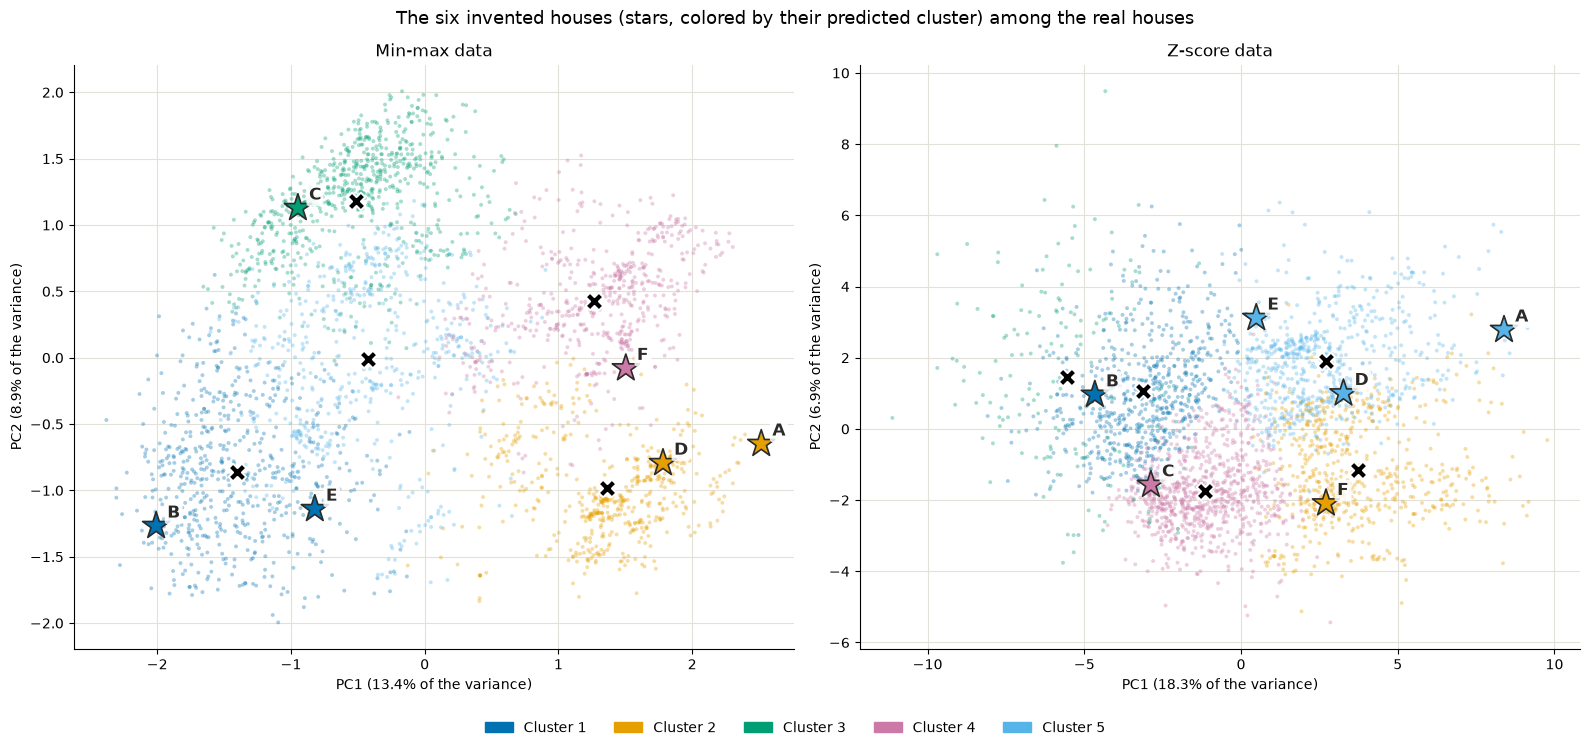

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5))
for ax, (name, fit) in zip(axes, fits.items()):
    model, reduced = fit["models"][THRESHOLD], fit["reduced"]
    ax.scatter(reduced[:, 0], reduced[:, 1], c=np.array(CLUSTER_COLORS)[model.labels_], s=8, alpha=0.35, linewidths=0)
    centers = model.cluster_centers_[:, :2]
    ax.scatter(centers[:, 0], centers[:, 1], marker="X", s=160, c="black", edgecolors="white", linewidths=1.4, zorder=3)
    points = new_components[name]
    clusters = model.predict(points[:, : fit["counts"][THRESHOLD]])
    ax.scatter(points[:, 0], points[:, 1], marker="*", s=420, c=np.array(CLUSTER_COLORS)[clusters],
               edgecolors=INK, linewidths=1.2, zorder=4)
    for house, (x, y_) in zip(X_new.index, points[:, :2]):
        ax.annotate(house[0], (x, y_), xytext=(8, 6), textcoords="offset points", fontsize=12, fontweight="bold",
                    color=INK, bbox={"boxstyle": "round,pad=0.15", "facecolor": "white", "edgecolor": "none", "alpha": 0.85},
                    zorder=5)
    first, second = fit["pca"].explained_variance_ratio_[:2]
    ax.set_title(f"{name} data", fontsize=12)
    ax.set_xlabel(f"PC1 ({first:.1%} of the variance)")
    ax.set_ylabel(f"PC2 ({second:.1%} of the variance)")
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
handles = [Patch(color=CLUSTER_COLORS[i], label=f"Cluster {i + 1}") for i in range(N_CLUSTERS)]
fig.legend(handles=handles, loc="lower center", ncol=N_CLUSTERS, frameon=False)
fig.suptitle("The six invented houses (stars, colored by their predicted cluster) among the real houses", fontsize=13)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

#### Interpretation of the new houses
- **The thresholds do not matter:** under min-max every house gets the same cluster at 80%, 90%, 95% and 98%, and the same holds under z-score. This matches notebook 08: the components dropped between the thresholds are small.
- **Intuitively right (min-max):** B lands in cluster 1 (old houses), C in cluster 3 (1960s ranch houses), D in cluster 2 (modern two-story houses) and F in cluster 4 (modern one-story houses, which include the new townhouses). For B, C, D and F all 15 most similar real houses are in the same cluster, and the distance to the own centroid is only 0.60 to 0.74 of the distance to the next one. D is the clearest case (0.599).
- **A is right in kind, not in price:** A lands in the modern two-story cluster 2, which matches its style. But its 15 nearest real houses have a median price of 398,800, while the cluster has 219,210. The clusters describe the type of house, and no cluster stands for luxury houses. A is also close to the border with cluster 4 (ratio 0.881).
- **E is the interesting case.** Min-max puts it into cluster 1, the cheap old houses, at both thresholds. By construction this is right: brick foundation, wood siding, detached garage and 1915 are exactly the categories of cluster 1. By value it is wrong: quality 8, a 2005 remodel and an excellent kitchen make it a better house than the typical member, and its nearest neighbors have a median price of 165,000 against 120,000 for the cluster. Its distance ratio of 0.852 shows that it lies near the border with cluster 5.
- **Z-score judges E differently:** it places E in the modern two-story cluster Z5, because under z-score the quality grades and the remodeling year count more than the building materials. But E lies almost exactly on the border (ratio 0.980), and only 20% of its 15 neighbors are in Z5. E is a house that really belongs between two groups. Which side it falls on depends on what the distance measures, so neither answer is simply right or wrong.
- **The other houses under z-score** land in the matching clusters: B in Z1 (old), C in Z4 (1960s), D and A in Z5 (modern two-story), F in Z2 (modern one-story).
- **Scaling of new houses:** the scaler uses the minimum and maximum of the real houses, not those of the new ones. All values of the six houses stay within 0–1, so none lies outside the range the model has seen.

#### Why must a new house pass through the PCA before the prediction?
The cell below tries three shortcuts that skip the fitted PCA.

In [16]:
model = fits["Min-max"]["models"][THRESHOLD]
count = fits["Min-max"]["counts"][THRESHOLD]
print(f"The model knows {model.cluster_centers_.shape[0]} centroids with {model.cluster_centers_.shape[1]} coordinates each")
print(f"A new house after encoding and scaling has {scaled_new.shape[1]} values")

# 1. Without PCA the house has the wrong number of values
try:
    model.predict(scaled_new.to_numpy())
except ValueError as error:
    print(f"Predicting from the scaled columns: ValueError: {error}")

# 2. Cutting the scaled columns to the right length gives an answer, but a meaningless one
cut = model.predict(scaled_new.to_numpy()[:, :count]) + 1
right = model.predict(new_components["Min-max"][:, :count]) + 1
print(f"First {count} scaled columns: clusters {cut.tolist()}")
print(f"Through the fitted PCA:       clusters {right.tolist()}")

# 3. A PCA fitted again on the new houses builds other axes
try:
    PCA(n_components=count).fit(scaled_new)
except ValueError as error:
    print(f"Fitting a new PCA on the 6 houses: ValueError: {error}")
own_axes = PCA(n_components=2).fit(scaled_new).components_
fitted_axes = fits["Min-max"]["pca"].components_[:2]
print(f"|cosine| between the PC1 of 6 new houses and the fitted PC1: {abs(own_axes[0] @ fitted_axes[0]):.3f}")

The model knows 5 centroids with 59 coordinates each
A new house after encoding and scaling has 205 values
Predicting from the scaled columns: ValueError: X has 205 features, but KMeans is expecting 59 features as input.
First 59 scaled columns: clusters [5, 5, 5, 5, 5, 4]
Through the fitted PCA:       clusters [2, 1, 3, 2, 1, 4]
Fitting a new PCA on the 6 houses: ValueError: n_components=59 must be between 0 and min(n_samples, n_features)=6 with svd_solver='full'
|cosine| between the PC1 of 6 new houses and the fitted PC1: 0.862


#### Interpretation: why the PCA transform is needed
- **The model lives in the PCA coordinates.** k-means was trained on the first 59 principal components, so its centroids have 59 coordinates, and these coordinates are positions along the PC axes, not values of features. A prediction measures the distance from the house to each centroid, which is only possible if the house is described in the same coordinates.
- **Without PCA the house has the wrong format:** after encoding and scaling it has 205 values, and scikit-learn refuses the prediction (`X has 205 features, but KMeans is expecting 59`).
- **Cutting the columns gives nonsense:** the first 59 scaled columns are one-hot columns such as `MS SubClass_120` or `MS Zoning_RL`. Comparing them with coordinates on PC1 to PC59 puts five of the six houses into cluster 5. With the fitted PCA they land in clusters 2, 1, 3, 2, 1 and 4.
- **The PCA must be the fitted one:** `pca.transform` subtracts the mean of the training houses (`pca.mean_`) and projects onto the training axes (`pca.components_`). A new PCA fitted on the six houses cannot even build 59 components (at most 6), and its own PC1 points in another direction than the trained PC1 (|cosine| 0.862 instead of 1).
- **The same holds for every step before it:** the house is encoded with the fitted one-hot encoder (same 205 columns) and scaled with the minimum and maximum of the training houses. The full chain is: encoder → scaler → PCA → k-means. All four steps must be the fitted ones, otherwise the house is measured with another ruler than the houses the model has learned from.